In [ ]:
'''
Номер в списке | Год (соответствует файлу) | Ошибка | Столбцы
7              | 2012                      | MAE    | C F J I H G

Street Name - Название улицы
Benchmarking Submission - Подача заявки на замер
Water per Square Foot - Потребление воды на квадратный фут
Weather Normalized Source Foot - Потребление здания с учетом генерации/передачи, потерь и погодных условий
Site EUI - Годовое потребление энергии зданием
Entry number - Просто уникальный номер подачи заявки как я понял

УБИРАЕМ:
Benchmarking Submission - Подача заявки на замер (подана или нет) УБИРАЕМ
Entry number - Просто уникальный номер подачи заявки как я понял (обратная корреляция с Benchmarking Submission на это намекает), тоже УБИРАЕМ
Water per Square Foot - Потребление воды на квадратный фут, там заполнено менее 300 значений, УБИРАЕМ
Street Name - вообще не заметил изменения ошибки как бы ни крутил эту колонку, УБРАТЬ

Вместо них возьмем:
GHG - Выбросы парниковых газов
Reported Building Square Footage - Поданая площадь здания
Reported Facility Type - Поданый тип строения
Borough - Район
'''

'\nНомер в списке | Год (соответствует файлу) | Ошибка | Столбцы\n7              | 2012                      | MAE    | C F J I H G\n\nStreet Name - Название улицы\nBenchmarking Submission - Подача заявки на замер\nWater per Square Foot - Потребление воды на квадратный фут\nWeather Normalized Source Foot - Потребление здания с учетом генерации/передачи, потерь и погодных условий\nSite EUI - Годовое потребление энергии зданием\nEntry number - Просто уникальный номер подачи заявки как я понял\n\nУБИРАЕМ:\nBenchmarking Submission - Подача заявки на замер (подана или нет) УБИРАЕМ\nWater per Square Foot - Потребление воды на квадратный фут, там заполнено менее 300 значений, УБИРАЕМ\nEntry number - Просто уникальный номер подачи заявки как я понял\n(обратная корреляция с Benchmarking Submission на это намекает), тоже УБИРАЕМ\nStreet Name - вообще не заметил изменения ошибки как бы ни крутил эту колонку, УБРАТЬ\n\nВместо них возьмем:\nGHG - Выбросы парниковых газов\nReported Building Square F

In [129]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error

In [130]:
df_orig = pd.read_excel("data.xls")
df_orig.head()

,BBL,Street Number,Street Name,Borough,Zip,Benchmarking Submission,Entry Number,Site EUI,Weather Normalized Source EUI,Water per Square Foot,ENERGY STAR Score,GHG,Reported Building Square Footage,Reported Facility Type,Number of Buildings,Reported BINs
0,1000050010,115,BROAD STREET,MANHATTAN,10004,No DOF Record as of 08/01/12,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1000090001,34,WHITEHALL STREET,MANHATTAN,10004,Yes,1518.0,157.9,437.4,NaN,27.0,12077.53,852840.0,Office,1.0,1000018
2,1000090014,17,STATE STREET,MANHATTAN,10004,Yes,312.0,91.5,278.7,NaN,61.0,4817.62,574105.0,Office,1.0,1000020
3,1000090029,24,WHITEHALL STREET,MANHATTAN,10004,Yes,52.0,137.2,306.6,6.66,41.0,10190.38,859807.0,Office,1.0,1000021
4,1000100014,33,WHITEHALL STREET,MANHATTAN,10004,No DOF Record as of 08/01/12,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [131]:
# Узнаю названия колонок
df_orig.columns

Index(['BBL', 'Street Number', 'Street Name', 'Borough', 'Zip',
       'Benchmarking Submission', 'Entry Number', 'Site EUI',
       'Weather Normalized Source EUI', 'Water per Square Foot',
       'ENERGY STAR Score', 'GHG', 'Reported Building Square Footage',
       'Reported Facility Type', 'Number of Buildings', 'Reported BINs'],
      dtype='str')

In [132]:
# Датафрейм с только выбранными колонками
df = df_orig[['Borough', 'Weather Normalized Source EUI', 'Site EUI', 'GHG', 'Reported Building Square Footage', 'Reported Facility Type' ,'ENERGY STAR Score']]
df.head()

,Borough,Weather Normalized Source EUI,Site EUI,GHG,Reported Building Square Footage,Reported Facility Type,ENERGY STAR Score
0,MANHATTAN,NaN,NaN,NaN,NaN,NaN,NaN
1,MANHATTAN,437.4,157.9,12077.53,852840.0,Office,27.0
2,MANHATTAN,278.7,91.5,4817.62,574105.0,Office,61.0
3,MANHATTAN,306.6,137.2,10190.38,859807.0,Office,41.0
4,MANHATTAN,NaN,NaN,NaN,NaN,NaN,NaN


In [133]:
# Всего 4081 строка
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4081 entries, 0 to 4080
Data columns (total 7 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Borough                           4081 non-null   str    
 1   Weather Normalized Source EUI     2319 non-null   float64
 2   Site EUI                          2319 non-null   float64
 3   GHG                               2309 non-null   float64
 4   Reported Building Square Footage  2423 non-null   float64
 5   Reported Facility Type            2535 non-null   str    
 6   ENERGY STAR Score                 1593 non-null   float64
dtypes: float64(5), str(2)
memory usage: 223.3 KB


In [134]:
# Выбросим почти пустые строки
# 5 - необходимое число не пустых полей в строке
df = df.dropna(axis = 0, thresh=5)
df.info()

<class 'pandas.DataFrame'>
Index: 2317 entries, 1 to 4079
Data columns (total 7 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Borough                           2317 non-null   str    
 1   Weather Normalized Source EUI     2317 non-null   float64
 2   Site EUI                          2317 non-null   float64
 3   GHG                               2309 non-null   float64
 4   Reported Building Square Footage  2317 non-null   float64
 5   Reported Facility Type            2311 non-null   str    
 6   ENERGY STAR Score                 1518 non-null   float64
dtypes: float64(5), str(2)
memory usage: 144.8 KB


In [135]:
# Удаляем строки, где отсутствуют данные о целевой переменной ENERGY STAR Score
df = df.dropna(subset=['ENERGY STAR Score'])
df.info()

<class 'pandas.DataFrame'>
Index: 1518 entries, 1 to 4076
Data columns (total 7 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Borough                           1518 non-null   str    
 1   Weather Normalized Source EUI     1518 non-null   float64
 2   Site EUI                          1518 non-null   float64
 3   GHG                               1515 non-null   float64
 4   Reported Building Square Footage  1518 non-null   float64
 5   Reported Facility Type            1518 non-null   str    
 6   ENERGY STAR Score                 1518 non-null   float64
dtypes: float64(5), str(2)
memory usage: 94.9 KB


In [136]:
from pandas.api.types import is_numeric_dtype, is_string_dtype
# Заполним пустые поля медианными значениями и обрежем выбросы по квантилям

for col in ['GHG', 'Reported Building Square Footage', 'Site EUI', 'Weather Normalized Source EUI']:
    df[col] = df[col].fillna(df[col].median())
    lo, hi = df[col].quantile([0.01, 0.99]) # Находим квантили
    df[col] = df[col].clip(lo, hi) # Обрезаем выбросы (слишком много или мало)
    df[col] = np.log1p(df[col]) # Натуральный логарифм подожмет сильно большие числа ближе к остальным, чтобы не было перекосов
df.info()

<class 'pandas.DataFrame'>
Index: 1518 entries, 1 to 4076
Data columns (total 7 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Borough                           1518 non-null   str    
 1   Weather Normalized Source EUI     1518 non-null   float64
 2   Site EUI                          1518 non-null   float64
 3   GHG                               1518 non-null   float64
 4   Reported Building Square Footage  1518 non-null   float64
 5   Reported Facility Type            1518 non-null   str    
 6   ENERGY STAR Score                 1518 non-null   float64
dtypes: float64(5), str(2)
memory usage: 94.9 KB


In [137]:
# Получилось многовато улиц, оставим только 10 самых популярных улиц, остальные будут Other
#top_streets = df['Street Name'].value_counts().head(10).index
#street_clean = df['Street Name'].where(df['Street Name'].isin(top_streets), 'OTHER')
# One Hot Coding
#ohc_tmp = pd.get_dummies(street_clean, prefix='Street')
#df = df.drop(columns='Street Name').join(ohc_tmp)
#df.info()

In [138]:
ohc_tmp = pd.get_dummies(df['Borough'])
df = df.drop(columns='Borough').join(ohc_tmp)
ohc_tmp = pd.get_dummies(df['Reported Facility Type'])
df = df.drop(columns='Reported Facility Type').join(ohc_tmp)

In [139]:
df.head()

,Weather Normalized Source EUI,Site EUI,GHG,Reported Building Square Footage,ENERGY STAR Score,BRONX,BROOKLYN,MANHATTAN,QUEENS,STATEN ISLAND,...,House of Worship,K-12 School,Medical Office,Office,Residence Hall/Dormitory,Retail,Senior Care Facility,Supermarket/Grocery,Warehouse (Refrigerated),Warehouse (Unrefrigerated)
1,6.083132,5.068275,9.399185,13.656328,27.0,False,False,True,False,False,...,False,False,False,True,False,False,False,False,False,False
2,5.633718,4.527209,8.480243,13.260569,61.0,False,False,True,False,False,...,False,False,False,True,False,False,False,False,False,False
3,5.728800,4.928702,9.229298,13.664464,41.0,False,False,True,False,False,...,False,False,False,True,False,False,False,False,False,False
5,5.042134,3.998201,7.521589,12.850001,76.0,False,False,True,False,False,...,False,False,False,True,False,False,False,False,False,False
6,5.533785,4.737075,8.076860,12.706824,58.0,False,False,True,False,False,...,False,False,False,True,False,False,False,False,False,False


In [140]:
# Разделяем выборку на train и test
labels = df['ENERGY STAR Score']
data = df.drop(['ENERGY STAR Score'], axis=1)

X_train, X_test, y_train, y_test = train_test_split(data, labels, test_size=0.3, random_state=1)
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(1062, 23)
(456, 23)
(1062,)
(456,)


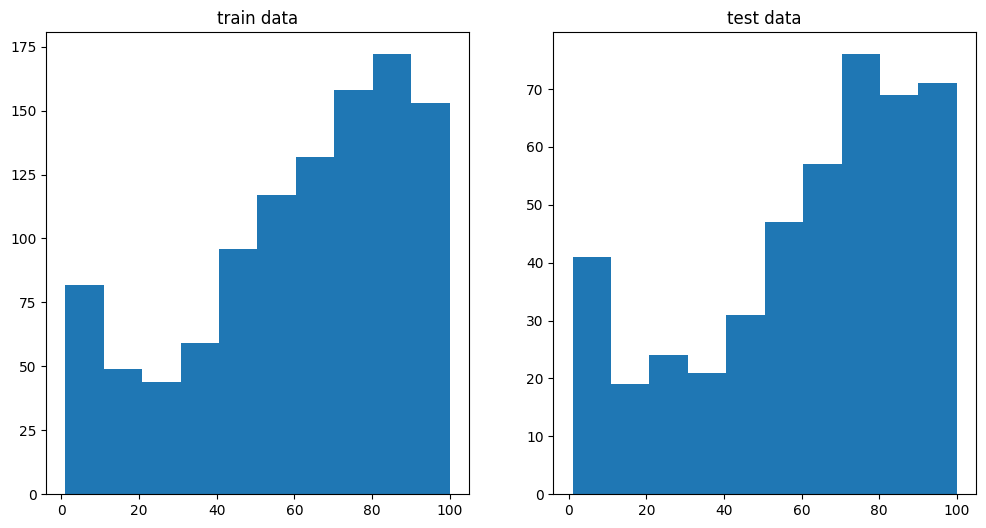

In [141]:
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.hist(y_train)
plt.title('train data')
plt.subplot(1, 2, 2)
plt.hist(y_test)
plt.title('test data')
plt.show()

In [142]:
# Обучаем модель линейной регрессии и оцениваем
lin_reg = LinearRegression(copy_X=True, fit_intercept=True, n_jobs=None)
lin_reg.fit(X_train, y_train)

y_pred = lin_reg.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
print(mae)

13.454186201521345


In [143]:
comparison = pd.DataFrame({
    'y_true': y_test.values,
    'y_pred': y_pred.round(1),
})
comparison['error'] = comparison['y_pred'] - comparison['y_true']
comparison['abs_error'] = comparison['error'].abs()
print(comparison.head(10))

   y_true  y_pred  error  abs_error
0    84.0    74.9   -9.1        9.1
1    75.0    76.3    1.3        1.3
2     8.0    61.2   53.2       53.2
3    74.0    68.6   -5.4        5.4
4    72.0    67.0   -5.0        5.0
5    59.0    55.7   -3.3        3.3
6    92.0    66.1  -25.9       25.9
7     2.0    30.8   28.8       28.8
8    43.0    38.1   -4.9        4.9
9    86.0    77.6   -8.4        8.4
